# 07 – Phân loại Cảnh báo Ô nhiễm, Tối ưu Ngưỡng & Kiểm toán Rò rỉ Dữ liệu (Issue #13, W11)

**Môn học:** INFO3020 – Nhập môn Khoa học Dữ liệu (*Introduction to Data Science*) – ĐH CMC<br>
**Dữ liệu nguồn:** `data/processed/air_pollution_final.parquet` (Baseline `VN001`) & `data/processed/air_pollution_extended_2022_2026.parquet` (Protocol A đơn trạm `VN001` & `VN003_OPENAQ_7441`)<br>
**Quy chuẩn áp dụng:** QCVN 05:2023/BTNMT — Giá trị giới hạn nồng độ bụi mịn $\text{PM}_{2.5}$ trung bình 24 giờ là $50{,}0\ \mu\text{g/m}^3$<br>
**Định vị khoa học & độ trễ ERA5:** Do khí tượng Open-Meteo ERA5 là dữ liệu tái phân tích (reanalysis) có độ trễ phát hành khoảng 5 ngày, thiết lập tại $h = 0$ giờ là **truy hồi tức thời lịch sử (retrospective historical nowcast)** tại thời điểm $t$, sử dụng thống kê $\text{PM}_{2.5}$ quá khứ kết thúc ở $t-1$ (`shift(1)`) và khí tượng đồng bộ tại $t$. Để đánh giá khả năng dự báo phòng ngừa thực thụ khi không còn chồng lấn cửa sổ 24 giờ, notebook mở rộng thực nghiệm sang các tầm $h \in \{1, 6, 12, 24\}$ giờ kèm vùng đệm loại bỏ (purge gap) nghiêm ngặt.

---

## Các Câu Hỏi Nghiên Cứu Cốt Lõi (RQ4)

1. **Định nghĩa Nhãn tương thích Quy chuẩn:** Xây dựng nhãn nhị phân $y_t$ tương thích chu kỳ 24h của QCVN 05:2023/BTNMT trên dữ liệu quan trắc gốc (không nội suy nhãn) và đối soát đầy đủ 4 quần thể dữ liệu.
2. **Kỹ nghệ Đặc trưng Quá khứ theo Trạm:** Tạo các đặc trưng trượt (`pm25_rolling_mean_24h`, `pm25_rolling_std_24h` từ $t-1$ trở về trước trên lưới giờ liên tục) và trễ `pm25_lag24` (đúng $t-24\text{h}$), loại trừ `pm10`, `pm25_was_missing`, `is_high_humidity_fog`.
3. **Bẫy Accuracy & Baseline Thực chứng:** Đối sánh `DummyClassifier(strategy='prior')` và `PersistenceRuleClassifier` (1 biến) với `LogisticRegression` và `RandomForestClassifier` qua PR-AUC (`average_precision_score`), FAR, Brier score và Confusion Matrix 2x2.
4. **Tối ưu Ngưỡng & Tầm Dự báo Tương lai:** Tinh chỉnh ngưỡng $\tau$ hoàn toàn trên tập Train OOF ($F_2$ score & Recall dưới ràng buộc Precision $\ge 0{,}60$), đồng thời kiểm tra suy giảm hiệu năng khi loại bỏ chồng lấn 24h ở $h \in \{1, 6, 12, 24\}$ giờ.
5. **Kiểm toán 4 Dạng Rò rỉ Dữ liệu:** Chứng nhận Target, Train-Test contamination (`validate_no_leakage`), Temporal (chronological split + purge gap) và Group leakage (Protocol A đơn trạm).


In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.classification import (
    DEFAULT_SPLIT_TIMESTAMP,
    PRIMARY_BASELINE_STATION,
    compute_coverage_and_outage_tables,
    prepare_classification_data,
    run_extended_classification_suite,
)

BASELINE_PATH = REPO_ROOT / "data" / "processed" / "air_pollution_final.parquet"
EXTENDED_PATH = REPO_ROOT / "data" / "processed" / "air_pollution_extended_2022_2026.parquet"
FIGURES_DIR = REPO_ROOT / "figures"
AUDIT_REPORT_PATH = REPO_ROOT / "reports" / "classification_leakage_audit.md"
DOCS_AUDIT_PATH = REPO_ROOT / "docs" / "leakage_audit.md"
RESULTS_REPORT_PATH = REPO_ROOT / "reports" / "classification_results.md"
FINDINGS_DOC_PATH = REPO_ROOT / "docs" / "classification_findings.md"

print(f"Baseline Parquet : {BASELINE_PATH.resolve()} (exists={BASELINE_PATH.exists()})")
print(f"Extended Parquet : {EXTENDED_PATH.resolve()} (exists={EXTENDED_PATH.exists()})")


Baseline Parquet : C:\Users\ASUS\Documents\GitHub\air-pollution-analysis\data\processed\air_pollution_final.parquet (exists=True)
Extended Parquet : C:\Users\ASUS\Documents\GitHub\air-pollution-analysis\data\processed\air_pollution_extended_2022_2026.parquet (exists=True)


## 1. Định nghĩa Nhãn QCVN 24h, Đối Soát 4 Quần Thể & Gián Đoạn Quan Trắc

$$ y_t = \mathbb{I}\left(\frac{1}{24}\sum_{i=0}^{23} \text{PM}_{2.5, t-i} \ge 50{,}0\right) $$
- Yêu cầu đủ `min_periods = 24` giờ hợp lệ liên tục trên lưới giờ; nếu có bất kỳ giờ thiếu nào trong cửa sổ 24h, nhãn là `NaN` để bảo toàn tính nguyên bản dữ liệu.
- Bảng đối soát dưới đây thống kê đồng thời 4 quần thể từ lưới thời gian đầy đủ đến tập evaluable cuối cùng, cùng danh sách các đợt mất tín hiệu liên tục dài nhất.


In [2]:
df_base = pd.read_parquet(BASELINE_PATH)
cov_base, gaps_base, monthly_base = compute_coverage_and_outage_tables(
    df_base, split_timestamp=DEFAULT_SPLIT_TIMESTAMP, use_split_column=False
)
print("ĐỐI SOÁT 4 QUẦN THỂ DỮ LIỆU — VN001 BASELINE:")
display(cov_base)

print("TOP ĐỢT GIÁN ĐOẠN PM2.5 LIÊN TỤC DÀI NHẤT:")
display(gaps_base.head(5))

X_tr_chk, y_tr_chk, X_te_chk, y_te_chk, meta_chk = prepare_classification_data(
    df_base, split_timestamp=DEFAULT_SPLIT_TIMESTAMP, station_id=PRIMARY_BASELINE_STATION
)
print("THỐNG KÊ MẪU SỐ VÀ PREVALENCE THỰC TẾ:")
print(f"  Train: {meta_chk['n_train_valid']:,} / {meta_chk['n_train_total']:,} giờ | Prevalence valid={meta_chk['train_prevalence_valid']:.2%} | all={meta_chk['train_prevalence_all']:.2%}")
print(f"  Test : {meta_chk['n_test_valid']:,} / {meta_chk['n_test_total']:,} giờ | Prevalence valid={meta_chk['test_prevalence_valid']:.2%} | all={meta_chk['test_prevalence_all']:.2%}")
print(f"  Số ô NaN đầu vào chưa impute (sẽ impute trong từng fold CV): Train={meta_chk['n_train_missing_cells']}, Test={meta_chk['n_test_missing_cells']}")
print(f"  Số đặc trưng đầu vào ({X_tr_chk.shape[1]} biến): {list(X_tr_chk.columns)}")


ĐỐI SOÁT 4 QUẦN THỂ DỮ LIỆU — VN001 BASELINE:


,Quần thể,Total (giờ),Train (giờ),Test (giờ),Positives Total,Positives Train,Positives Test,Prevalence (Train / Test)
0,1. Toàn bộ lưới thời gian (All grid),9044,4682,4362,1655,986,669,21.06% / 15.34%
1,2. Có quan trắc PM2.5 hợp lệ,7495,4279,3216,1655,986,669,23.04% / 20.80%
2,3. Đủ nhãn cửa sổ 24h (y_raw.notna()),5317,2994,2323,1655,986,669,32.93% / 28.80%
3,4. Đủ nhãn & đặc trưng trễ 24h (Evaluable),5267,2965,2302,1644,978,666,32.98% / 28.93%


TOP ĐỢT GIÁN ĐOẠN PM2.5 LIÊN TỤC DÀI NHẤT:


,Start,End,Duration (hours),Split
0,2026-06-19 11:00:00+07:00,2026-07-15 16:00:00+07:00,630,test
1,2025-12-14 10:00:00+07:00,2025-12-16 13:00:00+07:00,52,train
2,2025-11-30 00:00:00+07:00,2025-12-01 12:00:00+07:00,37,train
3,2025-09-30 09:00:00+07:00,2025-10-01 08:00:00+07:00,24,train
4,2025-08-19 01:00:00+07:00,2025-08-19 23:00:00+07:00,23,train


THỐNG KÊ MẪU SỐ VÀ PREVALENCE THỰC TẾ:
  Train: 2,965 / 4,682 giờ | Prevalence valid=32.98% | all=20.89%
  Test : 2,302 / 4,362 giờ | Prevalence valid=28.93% | all=15.27%
  Số ô NaN đầu vào chưa impute (sẽ impute trong từng fold CV): Train=0, Test=0
  Số đặc trưng đầu vào (14 biến): ['pm25_rolling_mean_24h', 'pm25_rolling_std_24h', 'pm25_lag24', 'temperature', 'relative_humidity', 'temp_humidity_interaction', 'wind_speed', 'is_calm_wind', 'precipitation', 'surface_pressure', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos']


## 2. Thực Thi Suite Phân Loại Đa Phạm Vi Theo Protocol A

Thực thi trọn bộ quy trình chống rò rỉ (`SimpleImputer` + `RobustScaler` trong `ColumnTransformer`, tinh chỉnh ngưỡng $\tau^*$ qua 5-fold `TimeSeriesSplit` trên Train, xác thực `validate_no_leakage`) trên cả 3 phạm vi độc lập theo từng trạm:
1. `VN001_baseline_2026_01_15` (`air_pollution_final.parquet`, mốc Issue #7)
2. `VN001_extended_80_20` (`air_pollution_extended_2022_2026.parquet`, trạm `VN001`, Test 0 ca dương $\to$ kiểm chứng cờ `UNESTIMABLE`)
3. `VN003_extended_2022_2025` (`air_pollution_extended_2022_2026.parquet`, trạm lịch sử `VN003`, đa năm 2022–2025)


In [3]:
suite_results = run_extended_classification_suite(
    baseline_path=BASELINE_PATH,
    extended_path=EXTENDED_PATH if EXTENDED_PATH.exists() else None,
    figures_dir=FIGURES_DIR,
    report_results_path=RESULTS_REPORT_PATH,
    findings_path=FINDINGS_DOC_PATH,
    report_audit_path=AUDIT_REPORT_PATH,
    docs_audit_path=DOCS_AUDIT_PATH,
)

res_base = suite_results["VN001_baseline"]
print(f"Các phạm vi đã hoàn thành: {list(suite_results.keys())}")
print(f"Ngưỡng tối ưu F2 (VN001 baseline): LogReg tau={res_base.best_threshold_logreg:.2f} | RF tau={res_base.best_threshold_rf:.2f}")
print(f"Ngưỡng ràng buộc Prec>=0.60      : LogReg tau={res_base.best_threshold_logreg_constrained:.2f} | RF tau={res_base.best_threshold_rf_constrained:.2f}")
if res_base.threshold_warnings:
    print("Cảnh báo bão hòa biên lưới trên OOF:")
    for w in res_base.threshold_warnings:
        print(f"  - {w}")


Cảnh báo bão hòa biên lưới (recall_constrained): tau*=0.10 chạm cận dưới 0.10 trên OOF (phổ xác suất phân tách mạnh hoặc đồng phẳng quanh cực trị hàm mục tiêu).


Cảnh báo bão hòa biên lưới (recall_constrained): tau*=0.10 chạm cận dưới 0.10 trên OOF (phổ xác suất phân tách mạnh hoặc đồng phẳng quanh cực trị hàm mục tiêu).


Cảnh báo bão hòa biên lưới (f2): tau*=0.10 chạm cận dưới 0.10 trên OOF (phổ xác suất phân tách mạnh hoặc đồng phẳng quanh cực trị hàm mục tiêu).


Cảnh báo bão hòa biên lưới (f2): tau*=0.10 chạm cận dưới 0.10 trên OOF (phổ xác suất phân tách mạnh hoặc đồng phẳng quanh cực trị hàm mục tiêu).


Cảnh báo bão hòa biên lưới (recall_constrained): tau*=0.10 chạm cận dưới 0.10 trên OOF (phổ xác suất phân tách mạnh hoặc đồng phẳng quanh cực trị hàm mục tiêu).


Cảnh báo bão hòa biên lưới (recall_constrained): tau*=0.10 chạm cận dưới 0.10 trên OOF (phổ xác suất phân tách mạnh hoặc đồng phẳng quanh cực trị hàm mục tiêu).


... (4 outputs left out)

Cảnh báo bão hòa biên lưới (recall_constrained): tau*=0.10 chạm cận dưới 0.10 trên OOF (phổ xác suất phân tách mạnh hoặc đồng phẳng quanh cực trị hàm mục tiêu).


Cảnh báo bão hòa biên lưới (f2): tau*=0.10 chạm cận dưới 0.10 trên OOF (phổ xác suất phân tách mạnh hoặc đồng phẳng quanh cực trị hàm mục tiêu).


Cảnh báo bão hòa biên lưới (f2): tau*=0.10 chạm cận dưới 0.10 trên OOF (phổ xác suất phân tách mạnh hoặc đồng phẳng quanh cực trị hàm mục tiêu).


Các phạm vi đã hoàn thành: ['VN001_baseline', 'VN001_extended', 'VN003_extended']
Ngưỡng tối ưu F2 (VN001 baseline): LogReg tau=0.43 | RF tau=0.32
Ngưỡng ràng buộc Prec>=0.60      : LogReg tau=0.10 | RF tau=0.10
Cảnh báo bão hòa biên lưới trên OOF:
  - Cảnh báo bão hòa biên lưới (recall_constrained): tau*=0.10 chạm cận dưới 0.10 trên OOF (phổ xác suất phân tách mạnh hoặc đồng phẳng quanh cực trị hàm mục tiêu).
  - Cảnh báo bão hòa biên lưới (recall_constrained): tau*=0.10 chạm cận dưới 0.10 trên OOF (phổ xác suất phân tách mạnh hoặc đồng phẳng quanh cực trị hàm mục tiêu).


## 3. Hiệu Năng Trên Tập Test Độc Lập & Đối Chứng Baseline (`VN001_baseline`)

- So sánh đầy đủ `DummyClassifier(strategy='prior')`, `PersistenceRuleClassifier` (ngưỡng 1 biến `pm25_rolling_mean_24h >= 50`), `Logistic Regression` và `Random Forest` theo hai cơ chế chọn ngưỡng ($F_2$ và ràng buộc Precision $\ge 0{,}60$).
- Bổ sung **False Alarm Rate (FAR)** và **Brier score** bên cạnh Accuracy, Precision, Recall, $F_1$, $F_2$, ROC-AUC, PR-AUC và ma trận nhầm lẫn 2x2.


In [4]:
print("BẢNG HIỆU NĂNG PHÂN LOẠI TRÊN TẬP TEST ĐỘC LẬP (VN001 BASELINE):")
display(res_base.metrics_table)


BẢNG HIỆU NĂNG PHÂN LOẠI TRÊN TẬP TEST ĐỘC LẬP (VN001 BASELINE):


,Model,Threshold,Accuracy,Precision,Recall,FAR,F1,F2,Brier,ROC-AUC,PR-AUC,"Confusion Matrix [TN, FP, FN, TP]",Status
0,Baseline (Prior Dummy),0.50,0.7107,0.0000,0.0000,0.0000,0.0000,0.0000,0.2073,0.5000,0.2893,"[[1636, 0], [666, 0]]",OK
1,Baseline (Persistence Rule >=50),0.50,0.9917,0.9865,0.9850,0.0055,0.9857,0.9853,0.0845,0.9997,0.9992,"[[1627, 9], [10, 656]]",OK
2,"Logistic Regression (Balanced, F2)",0.43,0.9809,0.9418,0.9955,0.0251,0.9679,0.9843,0.0143,0.9995,0.9989,"[[1595, 41], [3, 663]]",OK
3,Logistic Regression (Prec>=0.60),0.10,0.9014,0.7458,1.0000,0.1388,0.8544,0.9362,0.0143,0.9995,0.9989,"[[1409, 227], [0, 666]]",OK
4,"Random Forest (Balanced, F2)",0.32,0.9883,0.9610,1.0000,0.0165,0.9801,0.9920,0.0134,0.9995,0.9985,"[[1609, 27], [0, 666]]",OK
5,Random Forest (Prec>=0.60),0.10,0.8097,0.6033,1.0000,0.2677,0.7525,0.8838,0.0134,0.9995,0.9985,"[[1198, 438], [0, 666]]",OK


## 4. Đường cong Precision-Recall (PR Curve) vs Baseline Prevalence


Biểu đồ PR Curve: C:\Users\ASUS\Documents\GitHub\air-pollution-analysis\figures\precision_recall_curve.png (165,650 bytes)


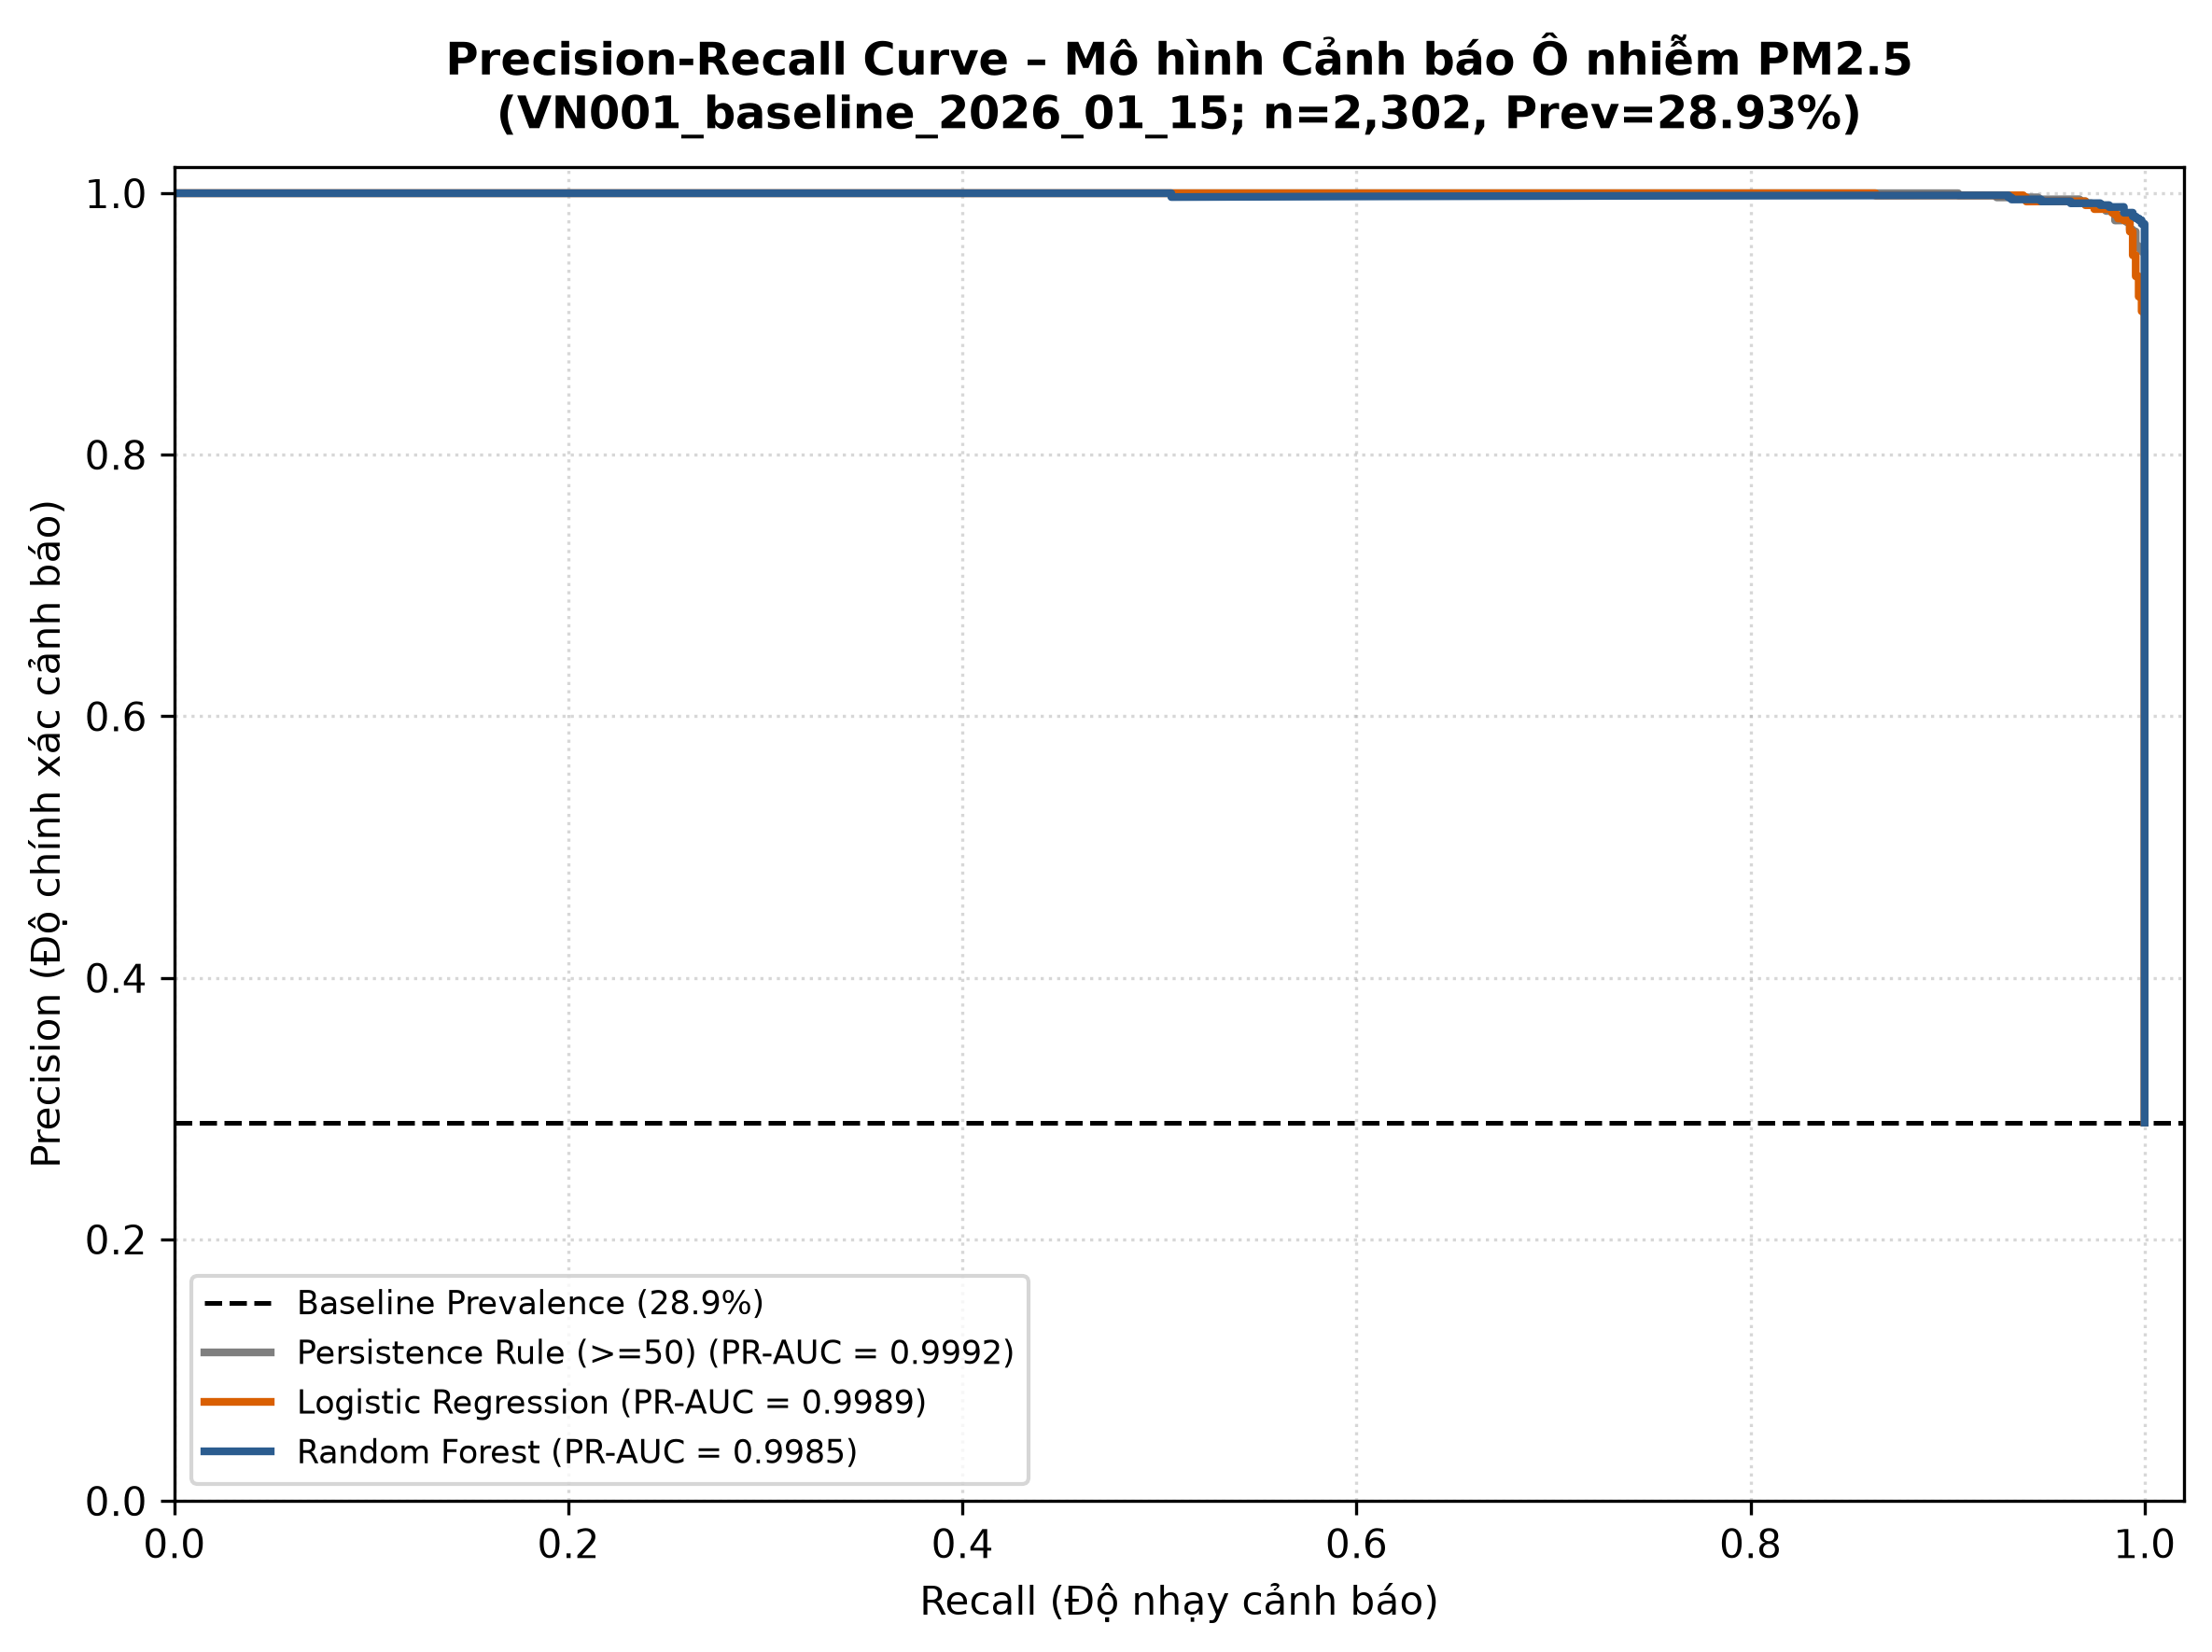

In [5]:
pr_path = FIGURES_DIR / "precision_recall_curve.png"
print(f"Biểu đồ PR Curve: {pr_path.resolve()} ({pr_path.stat().st_size:,} bytes)")
display(Image(filename=str(pr_path)))


## 5. Permutation Importance (`average_precision`, 20 repeats) & Logistic Regression Odds Ratios

- Đo mức suy giảm PR-AUC (`average_precision`) độc lập ngưỡng kèm khoảng tin cậy 95%, kết hợp hệ số & Odds Ratio ($\exp(\beta)$) từ Logistic Regression để đánh giá trung thực tác động khí tượng bên cạnh sự chi phối tự hồi quy ở $h = 0$.


BẢNG TẦM QUAN TRỌNG ĐẶC TRƯNG & ODDS RATIOS (VN001 BASELINE):


,Feature,MDI Importance,Permutation Mean,Permutation Std,CI95 Low,CI95 High,LogReg Coef (RobustScaler),Odds Ratio (exp(beta))
0,pm25_rolling_mean_24h,0.5763,0.474302,0.015432,0.467538,0.481065,11.5228,100990.2253
1,pm25_lag24,0.0855,0.001424,0.000715,0.001110,0.001737,-0.1148,0.8916
2,pm25_rolling_std_24h,0.0697,0.001000,0.000623,0.000727,0.001273,0.2653,1.3039
3,wind_speed,0.0097,0.000407,0.000379,0.000241,0.000573,-0.3781,0.6852
4,month_cos,0.0688,0.000192,0.000593,-0.000068,0.000452,0.6283,1.8744
5,surface_pressure,0.0525,0.000139,0.000113,0.000090,0.000189,0.0252,1.0255
6,temperature,0.0210,0.000081,0.000265,-0.000035,0.000197,-0.1931,0.8244
7,relative_humidity,0.0086,0.000031,0.000062,0.000004,0.000059,-0.1592,0.8528
8,is_calm_wind,0.0002,0.000001,0.000003,0.000000,0.000003,-0.4650,0.6281
9,month_sin,0.0248,0.000000,0.000000,0.000000,0.000000,0.0754,1.0783


Biểu đồ Feature Importance: C:\Users\ASUS\Documents\GitHub\air-pollution-analysis\figures\feature_importance.png (167,541 bytes)


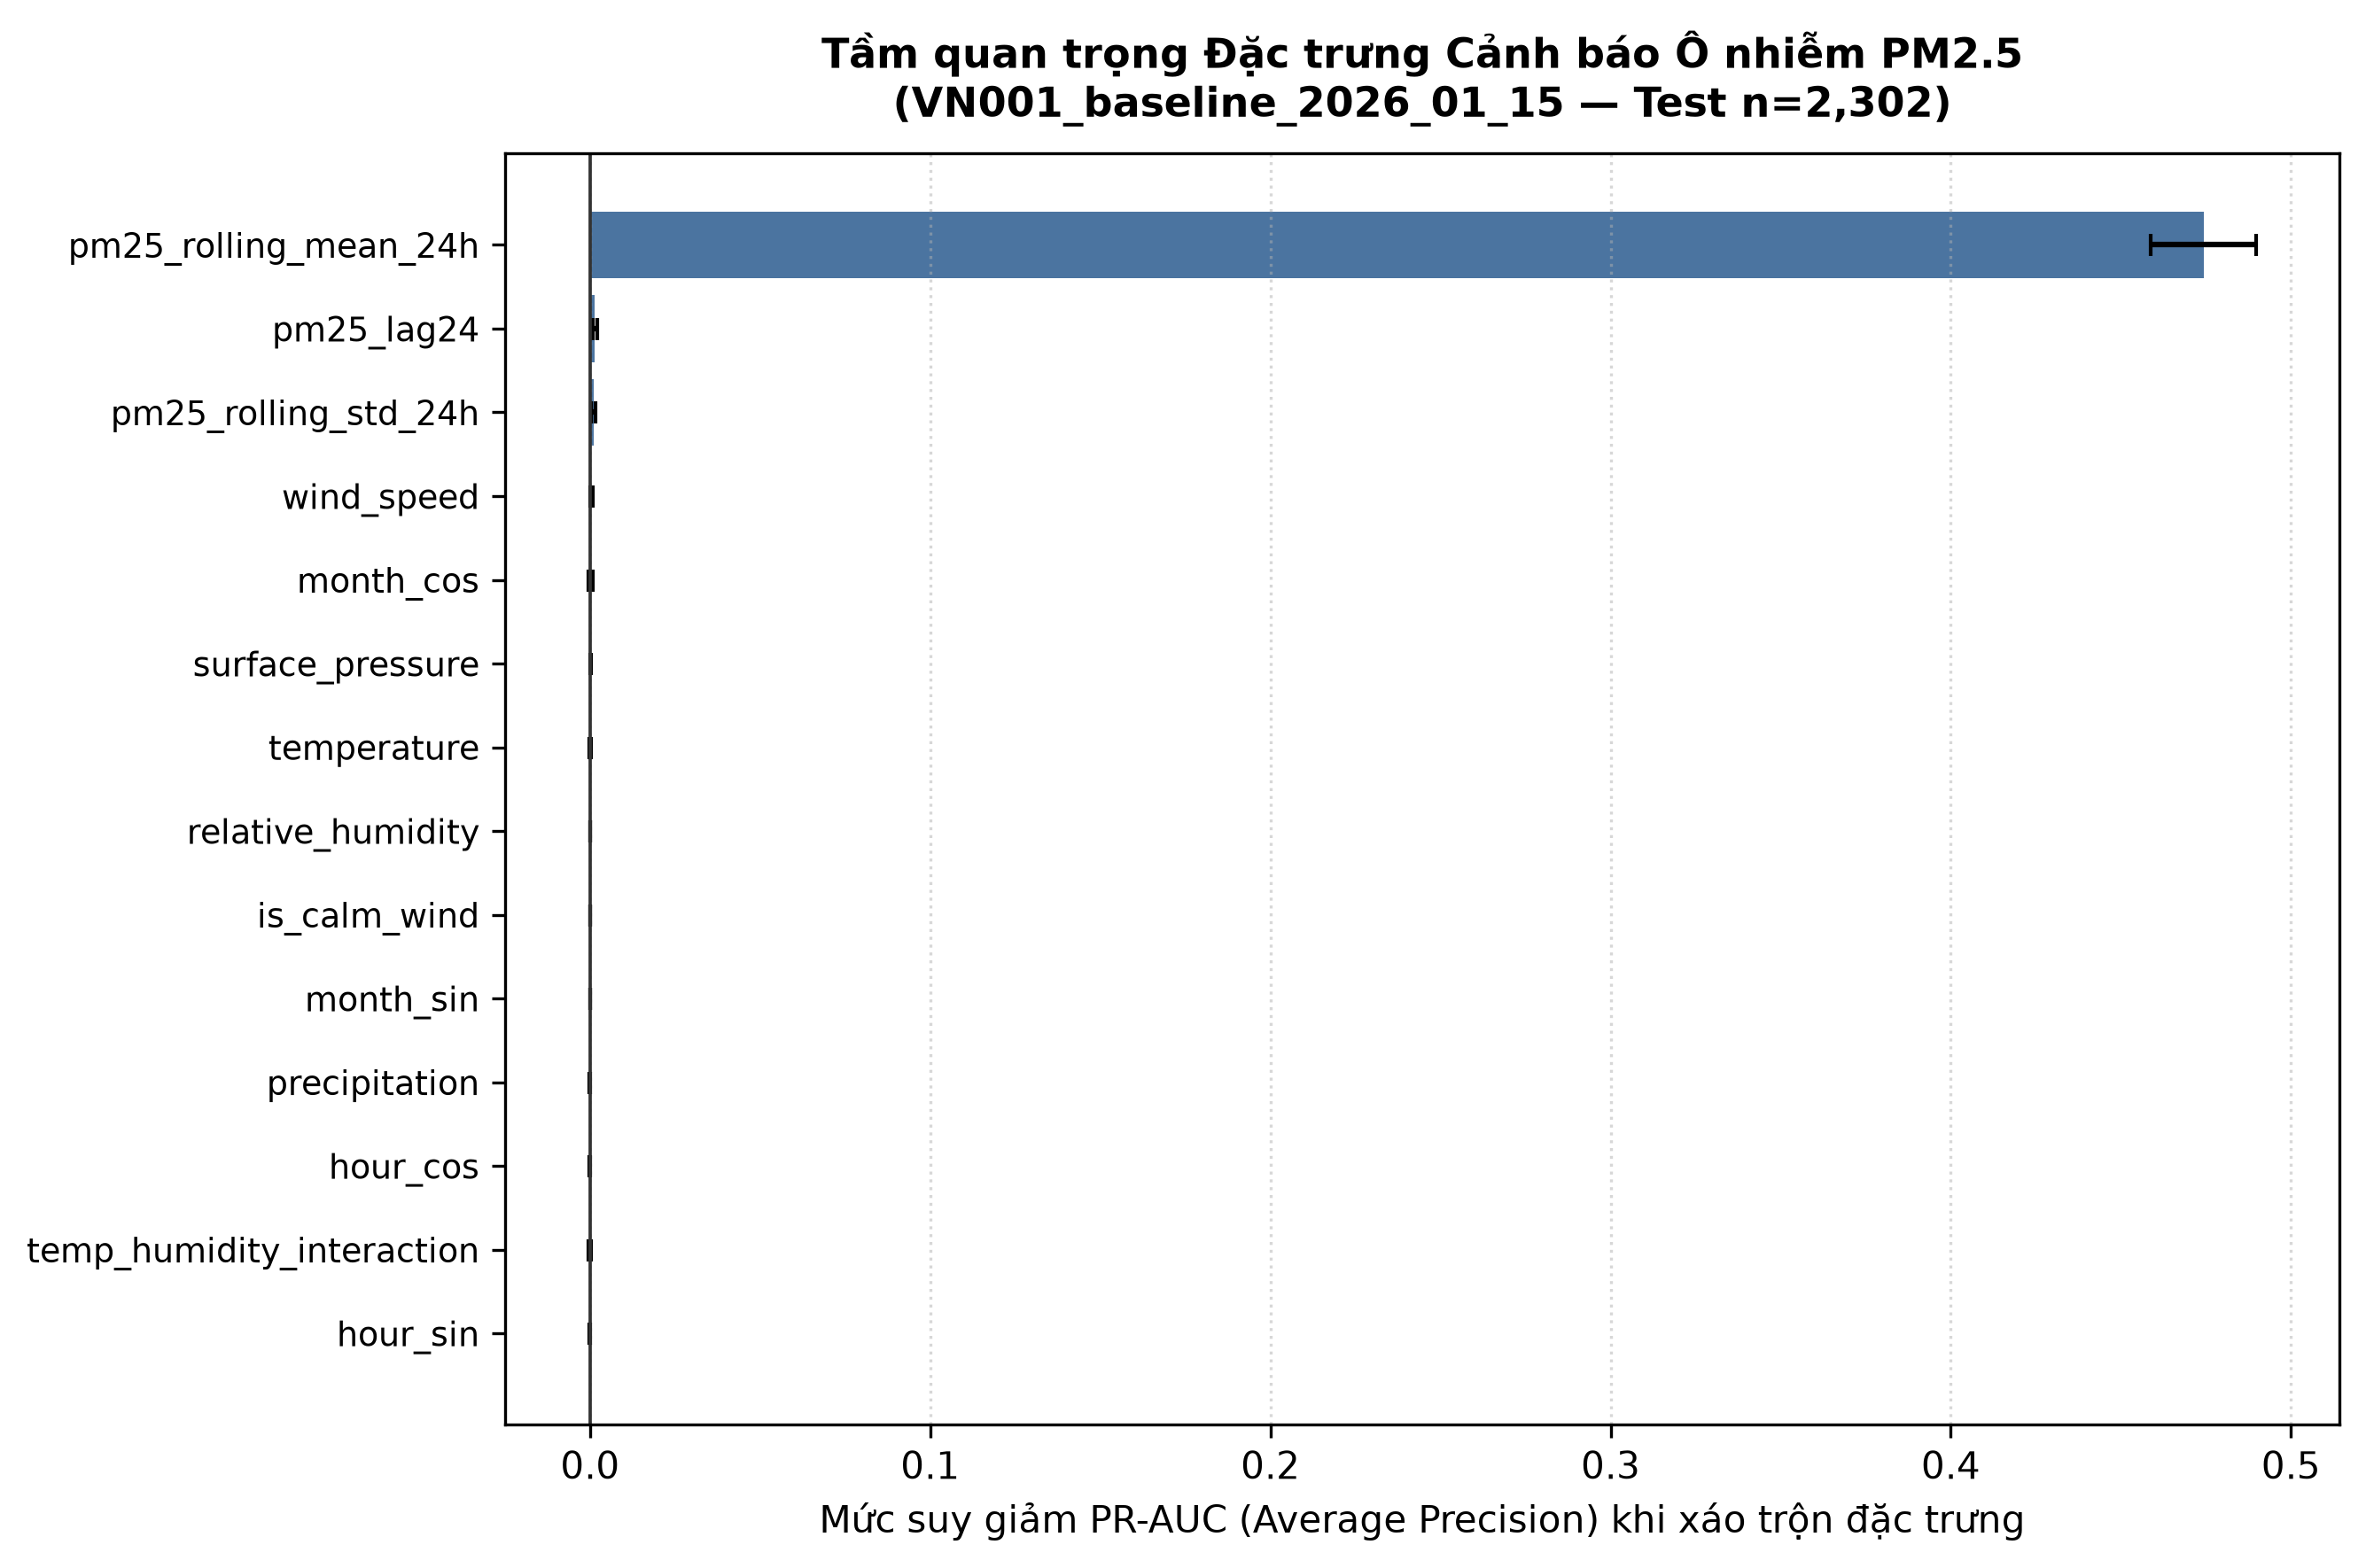

In [6]:
print("BẢNG TẦM QUAN TRỌNG ĐẶC TRƯNG & ODDS RATIOS (VN001 BASELINE):")
display(res_base.feature_importances)

feat_path = FIGURES_DIR / "feature_importance.png"
print(f"Biểu đồ Feature Importance: {feat_path.resolve()} ({feat_path.stat().st_size:,} bytes)")
display(Image(filename=str(feat_path)))


## 6. Cắt Giảm Đặc Trưng (Ablation) & Tầm Dự Báo Tương Lai $h \in \{0, 1, 6, 12, 24\}$ Giờ

- Định lượng rõ mức đóng góp của cửa sổ chồng lấn 23/24h so với `Lag24 + Met` và `Meteorology-Only`, đồng thời theo dõi PR-AUC suy giảm qua các tầm $h = 1, 6, 12, 24$ giờ khi áp dụng **purge gap** nghiêm ngặt tại biên Train/Test.


In [7]:
print("THỰC NGHIỆM FEATURE ABLATION & HORIZON DECAY (VN001 BASELINE):")
display(res_base.ablation_horizon_table)


THỰC NGHIỆM FEATURE ABLATION & HORIZON DECAY (VN001 BASELINE):


,Setting,n_train,n_test,Test Positives,Dummy PR-AUC,LogReg PR-AUC,LogReg Recall,RF PR-AUC,RF Recall,RF F2,Status
0,h=0h | Full (Rolling24 + Lag24 + Met),2965,2302,666,0.2893,0.9989,0.9955,0.9985,1.0000,0.9920,OK
1,h=0h | Lag24 + Met (No 24h Rolling),2965,2302,666,0.2893,0.7908,0.8529,0.7364,0.9940,0.6904,OK
2,h=0h | Meteorology + Time Only (No PM2.5),2994,2323,669,0.2880,0.4338,1.0000,0.5954,0.9985,0.6708,OK
3,h=1h | Full Feature Set,2936,2281,663,0.2907,0.9966,0.9804,0.9951,0.9940,0.9780,OK
4,h=6h | Full Feature Set,2803,2186,647,0.2960,0.9696,0.8887,0.9509,1.0000,0.7352,OK
5,h=12h | Full Feature Set,2647,2084,619,0.2970,0.9094,0.7205,0.8586,0.9984,0.7423,OK
6,h=24h | Full Feature Set,2369,1893,543,0.2868,0.7513,0.6041,0.5876,1.0000,0.7158,OK


## 7. Kiểm Chứng Mở Rộng Đa Phạm Vi (Protocol A), Backtest & Độ Nhạy Nội Suy Ngắn Hạn


EXPANDING-WINDOW TEMPORAL BACKTEST (TRAIN FOLDS — VN001 BASELINE):


,Fold,Train N,Val N,Val Positives,Val Prevalence,RF PR-AUC,RF Recall,RF Brier,Status
0,Fold 1,495,494,9,0.0182,0.9627,1.0000,0.0062,OK
1,Fold 2,989,494,50,0.1012,0.9908,0.4800,0.0261,OK
2,Fold 3,1483,494,139,0.2814,0.9834,0.8129,0.0627,OK
3,Fold 4,1977,494,411,0.8320,0.9981,1.0000,0.1012,OK
4,Fold 5,2471,494,312,0.6316,0.9887,0.9936,0.0375,OK



--- PHẠM VI VN001_extended_80_20 (Mùa sạch, Test 0 ca dương -> UNESTIMABLE) ---


,Model,Threshold,Accuracy,Precision,Recall,FAR,F1,F2,Brier,ROC-AUC,PR-AUC,"Confusion Matrix [TN, FP, FN, TP]",Status
0,Baseline (Prior Dummy),0.50,1.0000,NaN,NaN,0.0000,NaN,NaN,0.1070,NaN,NaN,"[[242, 0], [0, 0]]",UNESTIMABLE (0 positives in Test)
1,Baseline (Persistence Rule >=50),0.50,1.0000,NaN,NaN,0.0000,NaN,NaN,0.0696,NaN,NaN,"[[242, 0], [0, 0]]",UNESTIMABLE (0 positives in Test)
2,"Logistic Regression (Balanced, F2)",0.47,1.0000,NaN,NaN,0.0000,NaN,NaN,0.0008,NaN,NaN,"[[242, 0], [0, 0]]",UNESTIMABLE (0 positives in Test)
3,Logistic Regression (Prec>=0.60),0.10,0.9669,0.0,NaN,0.0331,NaN,NaN,0.0008,NaN,NaN,"[[234, 8], [0, 0]]",UNESTIMABLE (0 positives in Test)
4,"Random Forest (Balanced, F2)",0.28,1.0000,NaN,NaN,0.0000,NaN,NaN,0.0013,NaN,NaN,"[[242, 0], [0, 0]]",UNESTIMABLE (0 positives in Test)
5,Random Forest (Prec>=0.60),0.10,0.9876,0.0,NaN,0.0124,NaN,NaN,0.0013,NaN,NaN,"[[239, 3], [0, 0]]",UNESTIMABLE (0 positives in Test)



--- PHẠM VI VN003_extended_2022_2025 (Lịch sử 2022-2025) ---


,Model,Threshold,Accuracy,Precision,Recall,FAR,F1,F2,Brier,ROC-AUC,PR-AUC,"Confusion Matrix [TN, FP, FN, TP]",Status
0,Baseline (Prior Dummy),0.50,0.5019,0.0000,0.0000,0.0000,0.0000,0.0000,0.3107,0.5000,0.4981,"[[1726, 0], [1713, 0]]",OK
1,Baseline (Persistence Rule >=50),0.50,0.9860,0.9860,0.9860,0.0139,0.9860,0.9860,0.0732,0.9992,0.9992,"[[1702, 24], [24, 1689]]",OK
2,"Logistic Regression (Balanced, F2)",0.36,0.9756,0.9553,0.9977,0.0463,0.9760,0.9889,0.0120,0.9994,0.9995,"[[1646, 80], [4, 1709]]",OK
3,Logistic Regression (Prec>=0.60),0.10,0.9529,0.9145,0.9988,0.0927,0.9548,0.9807,0.0120,0.9994,0.9995,"[[1566, 160], [2, 1711]]",OK
4,"Random Forest (Balanced, F2)",0.30,0.9814,0.9703,0.9930,0.0301,0.9815,0.9884,0.0135,0.9983,0.9983,"[[1674, 52], [12, 1701]]",OK
5,Random Forest (Prec>=0.60),0.10,0.9256,0.8707,0.9988,0.1472,0.9304,0.9703,0.0135,0.9983,0.9983,"[[1472, 254], [2, 1711]]",OK


... (2 outputs left out)

Dịch chuyển theo năm trên Test (VN003):


,Test Year,N (hours),Positives,Prevalence,RF PR-AUC,RF Recall,RF FAR,Status
0,2024,1576,873,0.5539,0.9986,0.9920,0.0284,OK
1,2025,1863,840,0.4509,0.9980,0.9917,0.0166,OK


Kiểm tra độ nhạy `pm25_derived_interpolated` chỉ cho đặc trưng Train (VN003):


,Setting,n_train,n_test,Test Positives,Dummy PR-AUC,LogReg PR-AUC,LogReg Recall,RF PR-AUC,RF Recall,RF F2,Status,Train Recovered Rows
0,Observed-Only Features & Labels (Chính thức),10636,3439,1713,0.4981,0.9995,0.9977,0.9983,0.993,0.9884,OK,0
1,Train Derived Features (<=3h) + Observed Labels,10702,3439,1713,0.4981,0.9995,0.9977,0.9985,0.993,0.9886,OK,66


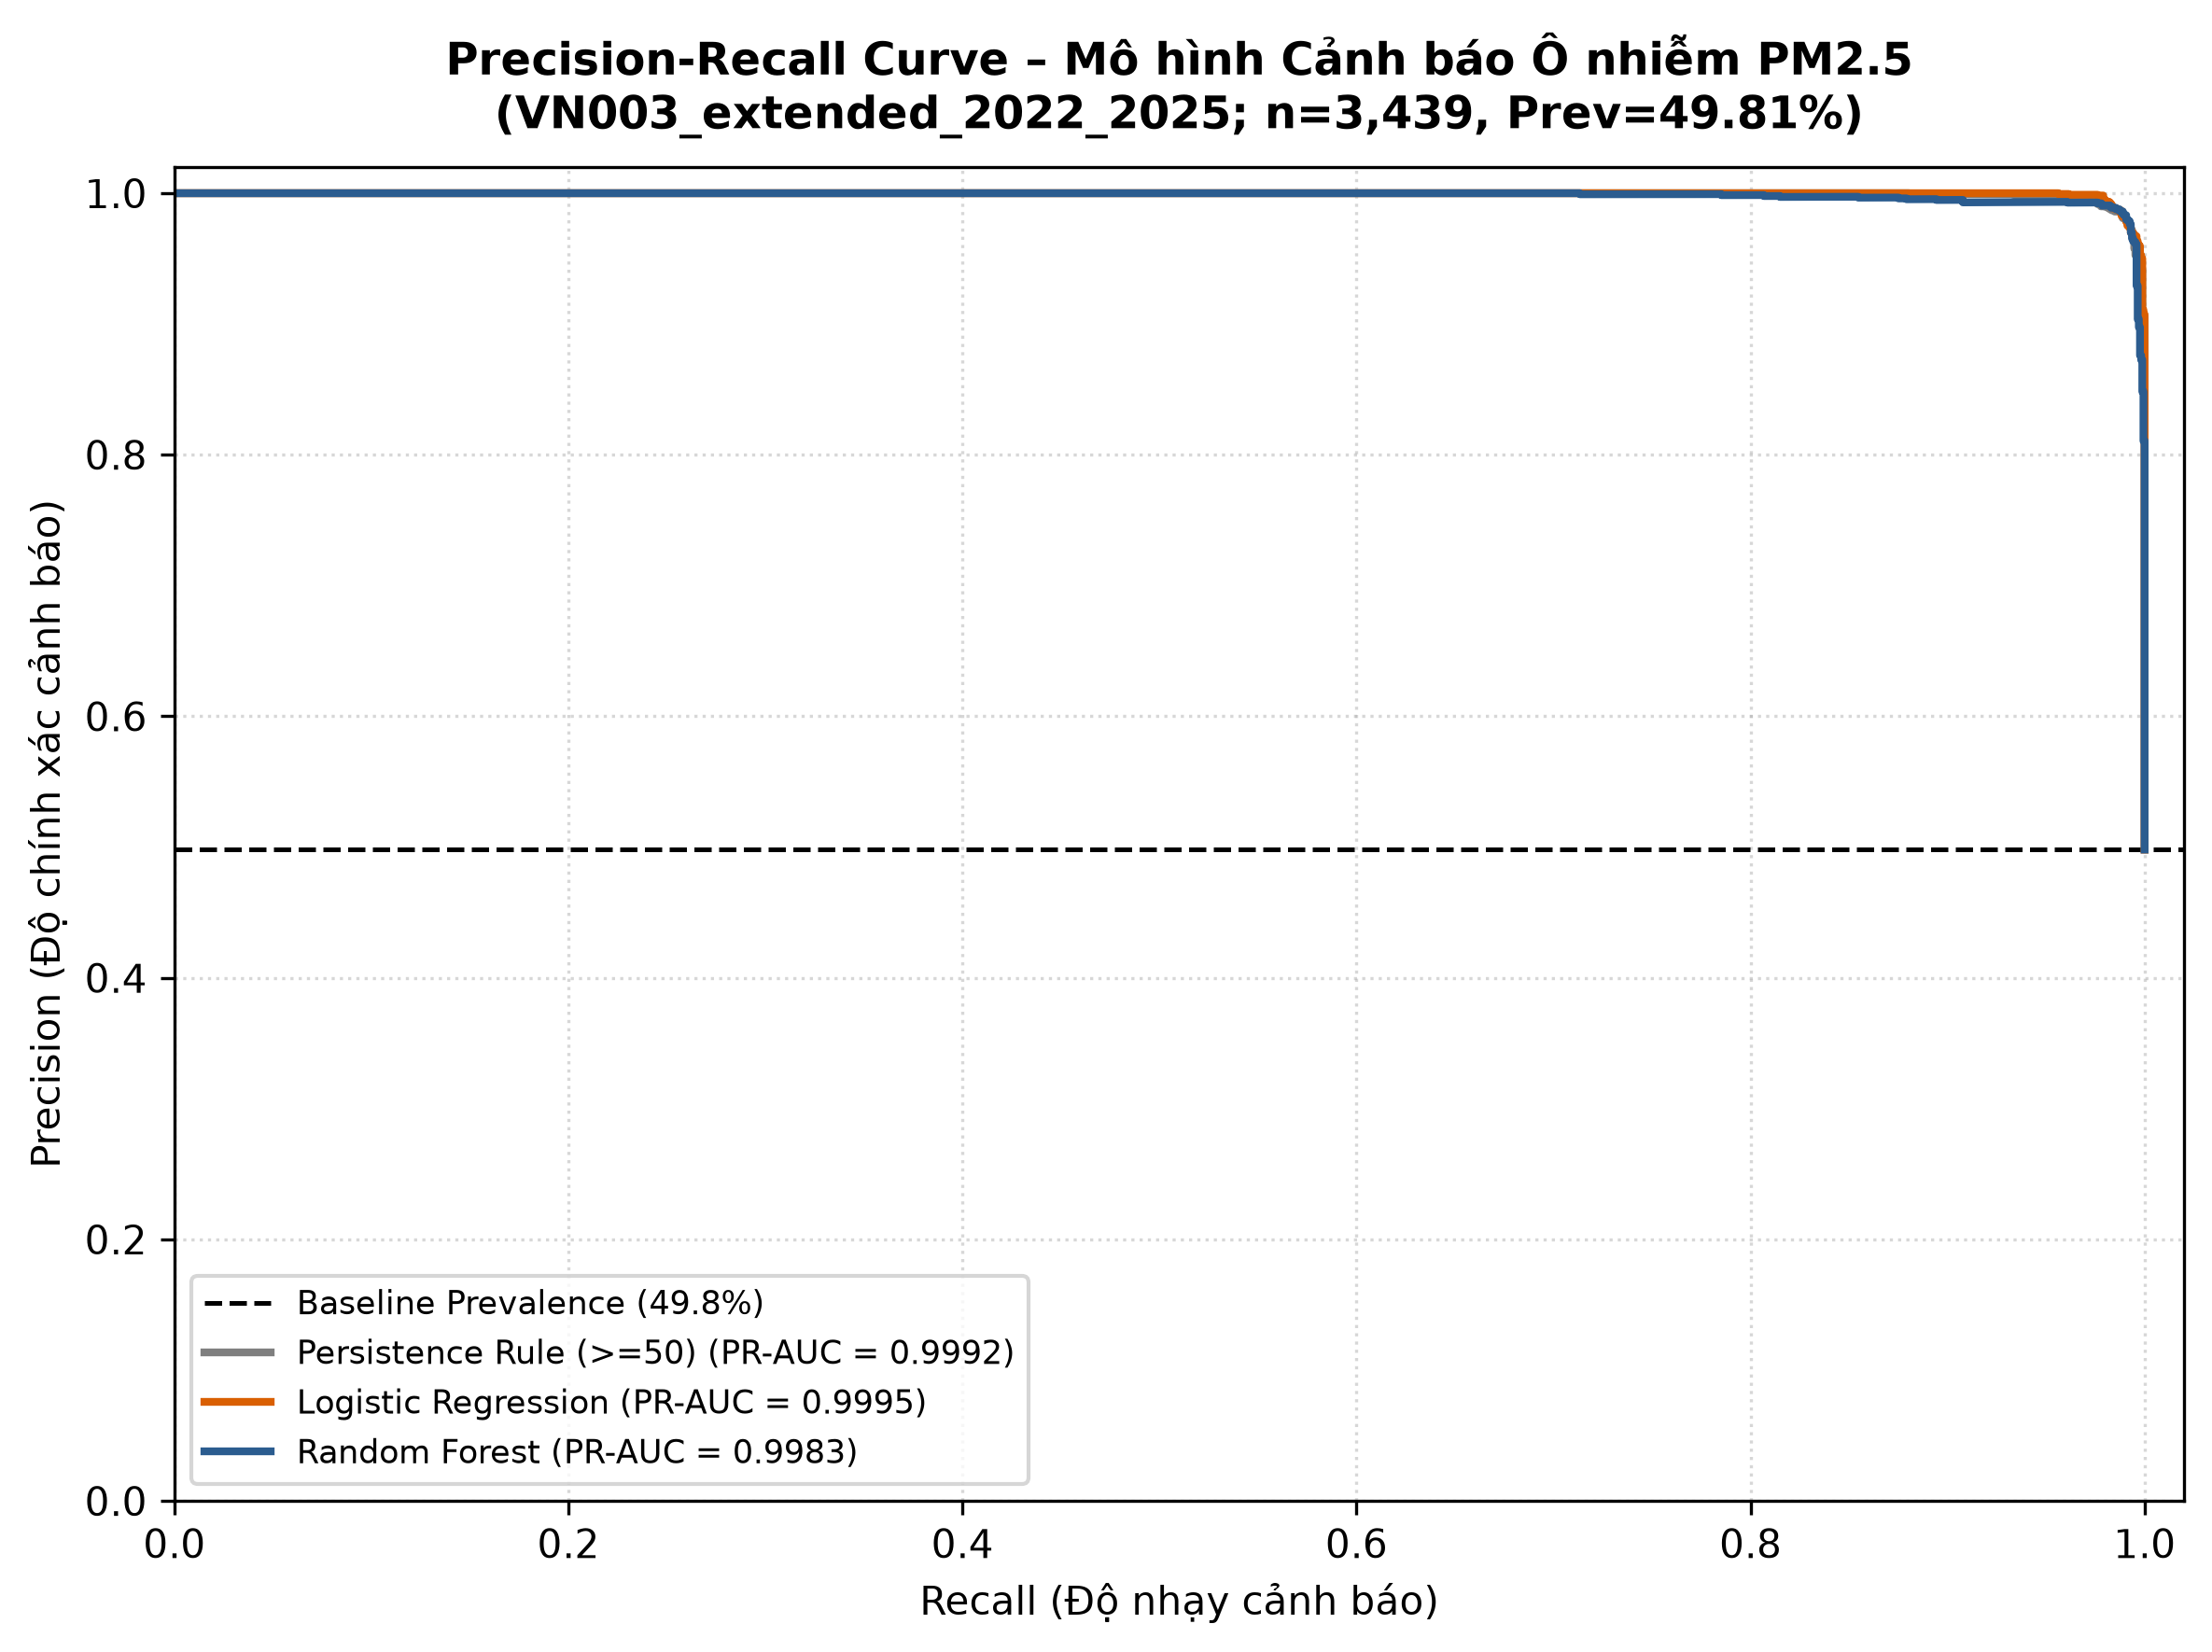

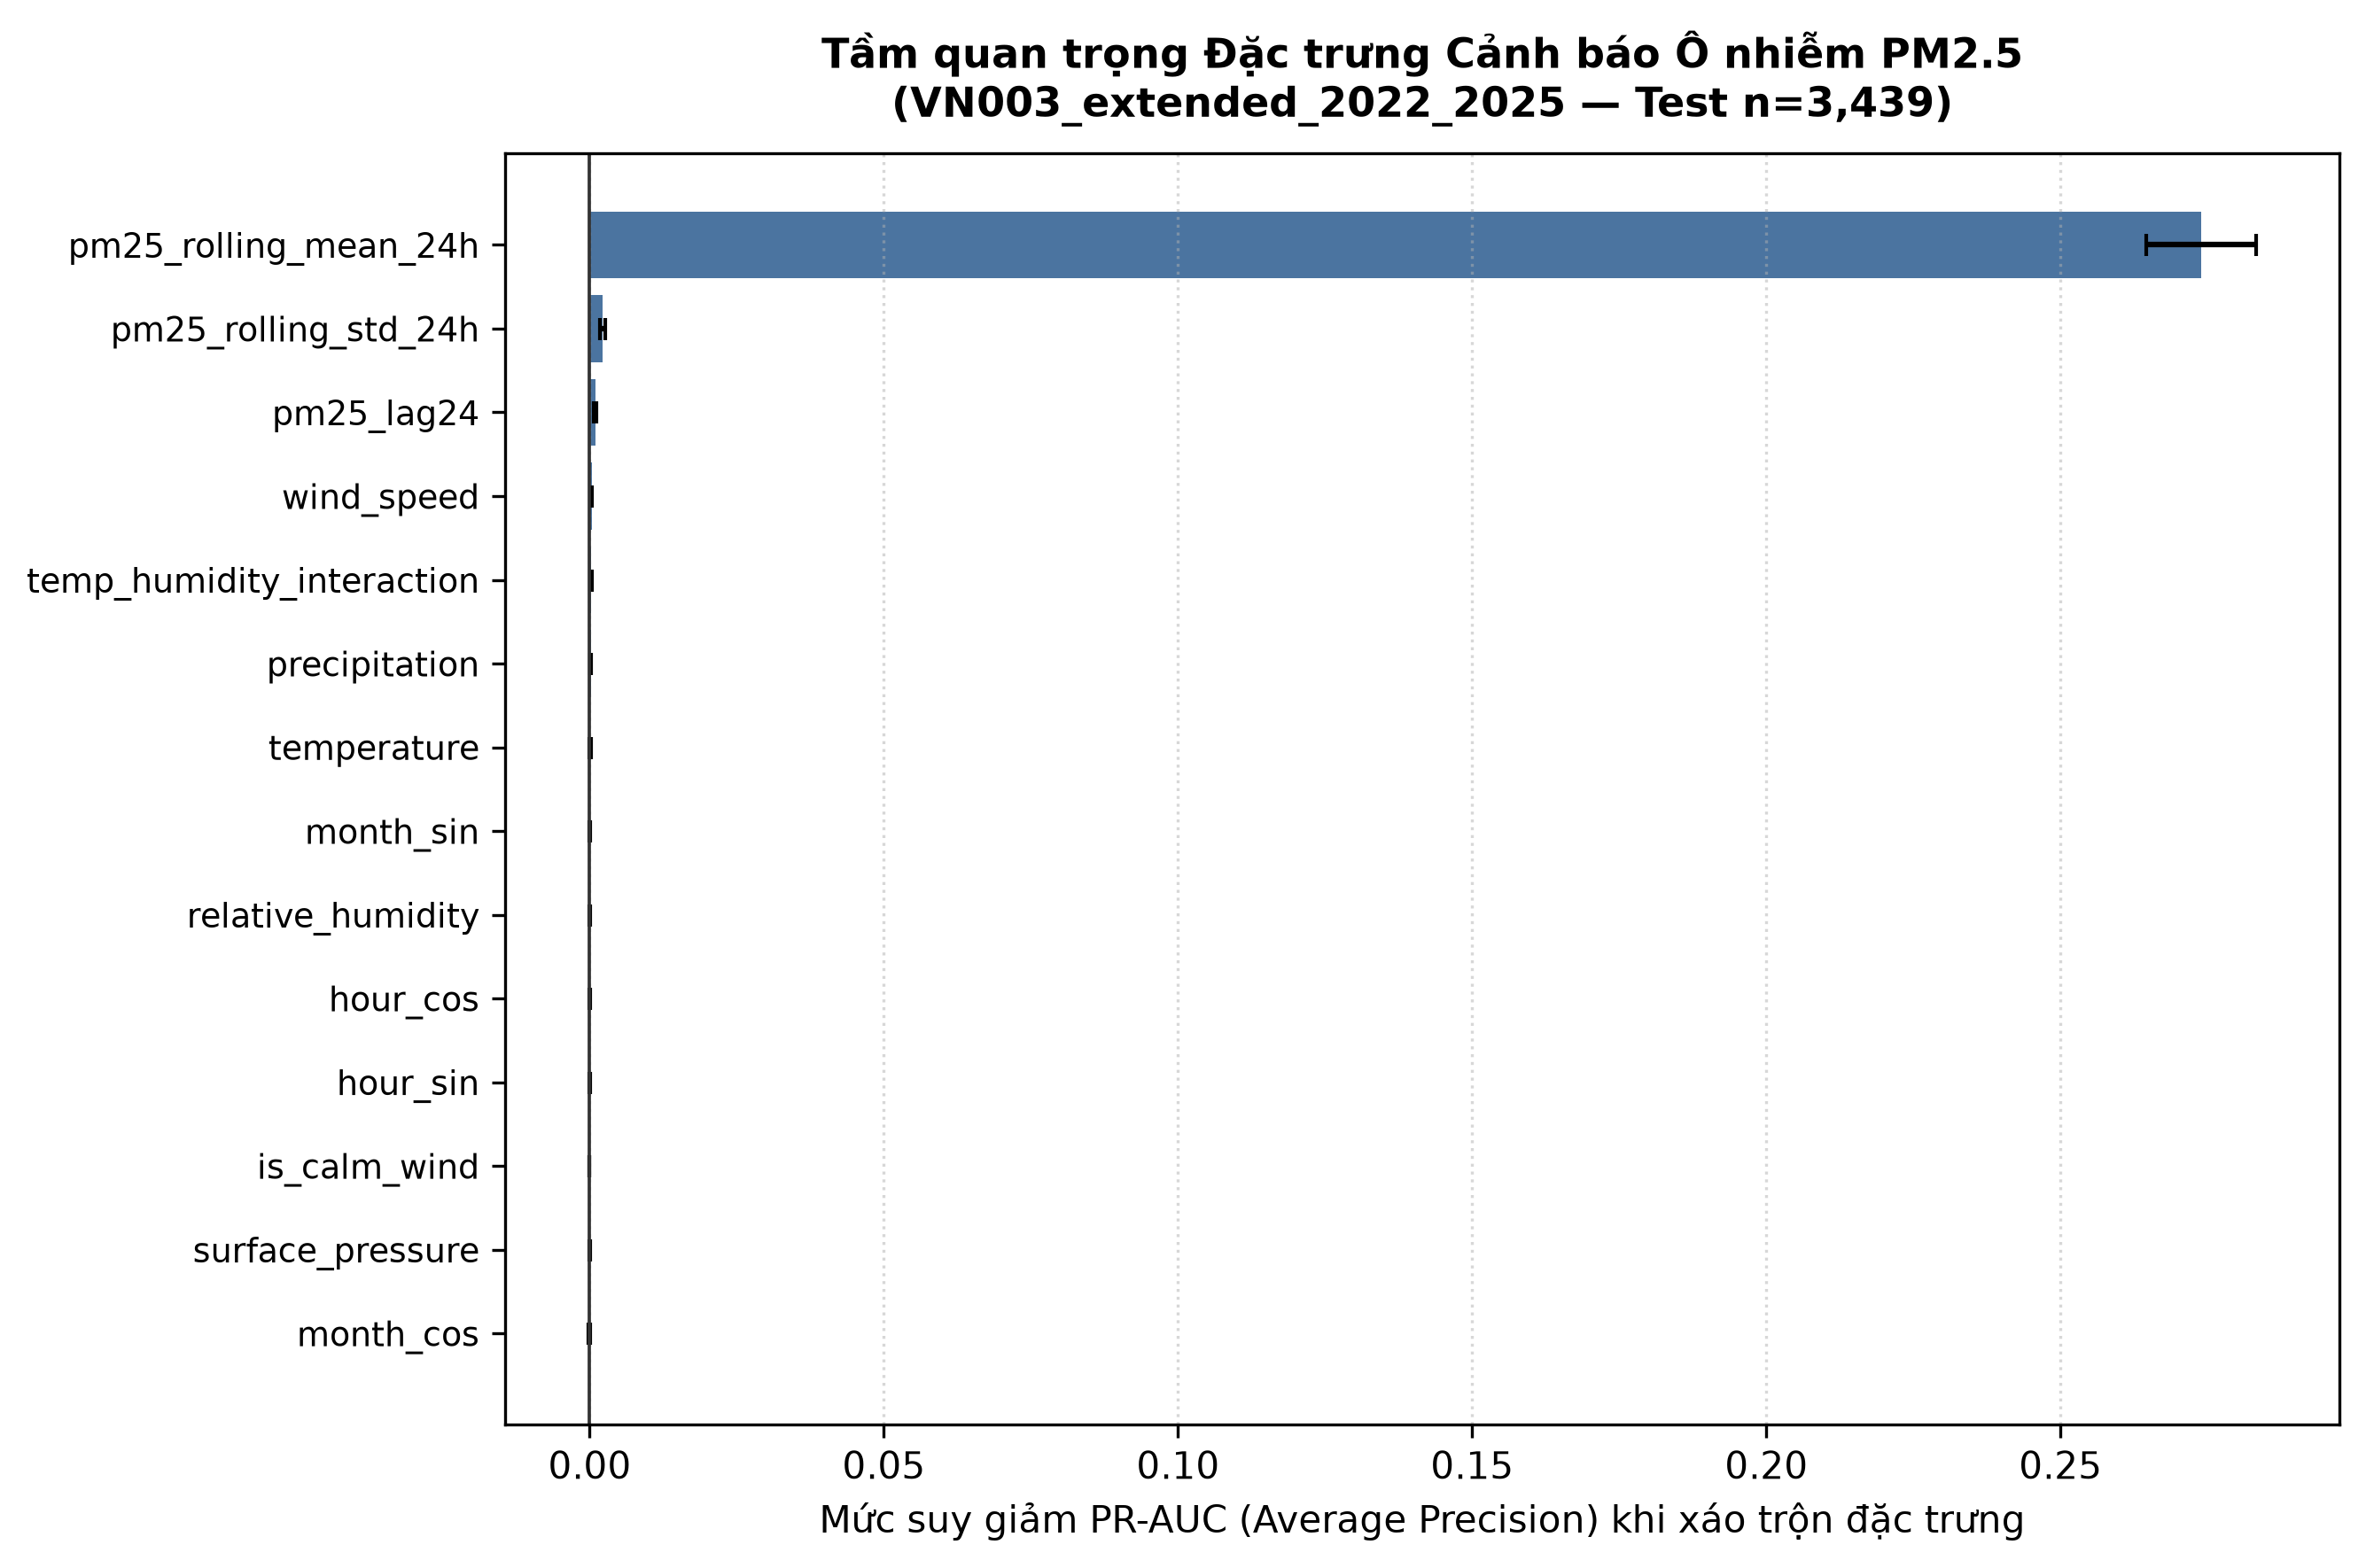

In [8]:
print("EXPANDING-WINDOW TEMPORAL BACKTEST (TRAIN FOLDS — VN001 BASELINE):")
display(res_base.backtest_table)

if "VN001_extended" in suite_results:
    res_ext1 = suite_results["VN001_extended"]
    print("\n--- PHẠM VI VN001_extended_80_20 (Mùa sạch, Test 0 ca dương -> UNESTIMABLE) ---")
    display(res_ext1.metrics_table)

if "VN003_extended" in suite_results:
    res_vn003 = suite_results["VN003_extended"]
    print("\n--- PHẠM VI VN003_extended_2022_2025 (Lịch sử 2022-2025) ---")
    display(res_vn003.metrics_table)
    print("Feature Ablation & Horizon Decay (VN003):")
    display(res_vn003.ablation_horizon_table)
    print("Dịch chuyển theo năm trên Test (VN003):")
    display(res_vn003.annual_drift_table)
    if res_vn003.derived_sensitivity_table is not None:
        print("Kiểm tra độ nhạy `pm25_derived_interpolated` chỉ cho đặc trưng Train (VN003):")
        display(res_vn003.derived_sensitivity_table)
    fig_vn003_pr = FIGURES_DIR / "precision_recall_curve_vn003_extended.png"
    if fig_vn003_pr.exists():
        display(Image(filename=str(fig_vn003_pr)))
    fig_vn003_fi = FIGURES_DIR / "feature_importance_vn003_extended.png"
    if fig_vn003_fi.exists():
        display(Image(filename=str(fig_vn003_fi)))


## 8. Biên bản Kiểm toán 4 Dạng Rò rỉ Dữ liệu & Tệp Bàn Giao Chính Thức


In [9]:
for p in [AUDIT_REPORT_PATH, DOCS_AUDIT_PATH, RESULTS_REPORT_PATH, FINDINGS_DOC_PATH]:
    print(f"Artifact đã ghi: {p.resolve()} (exists={p.exists()}, size={p.stat().st_size:,} bytes)")

display(Markdown(res_base.leakage_audit_markdown))


Artifact đã ghi: C:\Users\ASUS\Documents\GitHub\air-pollution-analysis\reports\classification_leakage_audit.md (exists=True, size=6,694 bytes)
Artifact đã ghi: C:\Users\ASUS\Documents\GitHub\air-pollution-analysis\docs\leakage_audit.md (exists=True, size=6,694 bytes)
Artifact đã ghi: C:\Users\ASUS\Documents\GitHub\air-pollution-analysis\reports\classification_results.md (exists=True, size=24,538 bytes)
Artifact đã ghi: C:\Users\ASUS\Documents\GitHub\air-pollution-analysis\docs\classification_findings.md (exists=True, size=7,003 bytes)


# Biên Bản Kiểm Toán Rò Rỉ Dữ Liệu Phân Loại (Data Leakage Audit) — Issue #13 & Task D14

> **Căn cứ học thuật:** Slide W11 & Quy định liêm chính học thuật INFO3020.
> **Mốc chia thời gian kiểm chứng:** `2026-01-15 00:00:00+07:00`
> **Kích thước tập hợp lệ kiểm chứng:** Train = 2,965 giờ (ô thiếu đầu vào: 0) | Test = 2,302 giờ (ô thiếu đầu vào: 0)

---

## 1. Kiểm toán 4 Dạng Rò rỉ Dữ liệu Cốt lõi & Bằng chứng Thực thi

| Dạng Rò Rỉ | Rủi ro Tiềm ẩn | Biện pháp Phòng ngừa & Bằng chứng Kiểm chứng | Kết luận |
|---|---|---|:---:|
| **1. Target Leakage (Rò rỉ Mục tiêu)** | Dùng biến phái sinh trực tiếp từ mục tiêu (`pm25_was_missing`), dùng biến đồng thời `pm10`, hoặc để đặc trưng trượt nhìn thấy giá trị tại $t$. | Cấm tuyệt đối `pm25`, `pm10`, `pm25_was_missing`, `is_high_humidity_fog` trong `FORBIDDEN_CLASSIFICATION_COLS` (raise `ValueError`). Đặc trưng trượt bắt buộc `shift(1)` (từ $t-1$ trở về trước) trên lưới giờ liên tục; kiểm chứng bằng unit test thay đổi `pm25[t] = 999` không làm biến thiên bất kỳ đặc trưng nào tại $t$. | **PASS** |
| **2. Train-Test Contamination (Nhiễm chéo Train-Test)** | Tham số imputer, scaler hoặc ngưỡng $\tau$ học từ tập Test hoặc impute toàn cục trước CV. | Không còn impute trong `prepare_classification_data`. `SimpleImputer(median)` và `RobustScaler()` nằm bên trong `Pipeline([('preprocessor', ColumnTransformer(...)), ('clf', ...)])`; từng fold của `TimeSeriesSplit(5)` chỉ fit trên `X_train.iloc[tr_idx]`; ngưỡng $\tau^*$ bất biến trước đột biến `y_test`; kiểm chứng sau fit bằng `src.cleaning_pipeline.validate_no_leakage()`. | **PASS** |
| **3. Temporal Leakage (Rò rỉ Thứ tự Thời gian)** | Chia ngẫu nhiên hoặc để nhãn $y_{t+h}$ ở cuối Train chồng lấn sang miền Test. | Phân chia tuyến tính kiểm chứng `ts_train.max() < ts_test.min()`. Khi tầm dự báo $h > 0$, áp dụng purge gap `t + h < split_timestamp` loại bỏ mọi mẫu cuối Train có cửa sổ nhãn chạm Test. | **PASS** |
| **4. Group / Station Leakage (Rò rỉ Cụm trạm)** | Gộp nhiều trạm lệch pha thời gian (`VN001` vs `VN003`) làm nhiễu rolling hoặc làm lộ ranh giới thời gian trạm khác. | Áp dụng Protocol A đơn trạm (`station_id` rõ ràng). `_select_single_station()` từ chối fail-closed nếu phát hiện > 1 trạm khi chưa chỉ định `station_id`. `engineer_classification_features()` nhóm độc lập theo `station_id` bảo đảm 24h đầu trạm B luôn là `NaN`, không tràn từ trạm A. | **PASS** |

---

## 2. Giải trình Loại trừ Kỹ thuật Tổng hợp Mẫu SMOTE

- **Nguyên nhân loại trừ:** SMOTE (*Synthetic Minority Over-sampling Technique*) nội suy tuyến tính giữa các hàng không kề nhau theo thời gian trong không gian đa biến.
- **Hệ quả trên chuỗi thời gian khí tượng:** Nội suy lân cận ghép cặp hai ngày khác mùa/khác bối cảnh synop, tạo ra bước nhảy phi vật lý giữa gió, áp suất và nhiệt-ẩm, đồng thời phá vỡ cấu trúc tự tương quan và ranh giới thời gian giữa các đợt ô nhiễm.
- **Giải pháp thay thế chuẩn mực:** Áp dụng `class_weight='balanced'` kết hợp tinh chỉnh ngưỡng $\tau$ trên OOF của Train theo $F_2$ và `Recall` dưới ràng buộc `Precision >= 0.60`.

---

## 3. Giải trình Chồng lấn Cửa sổ (Window Overlap) tại $h=0$ & Độ trễ Reanalysis ERA5

- **Tiêu chí cảnh giác (Slide W11 Takeaway #4):** *"Nghi ngờ ngay lập tức nếu PR-AUC hoặc Recall đạt > 99%"*.
- **Kết quả thực nghiệm tại tầm truy hồi tức thời ($h=0$):**
  - Logistic Regression: Recall = 99.55%, PR-AUC = 0.9989
  - Random Forest: Recall = 100.00%, PR-AUC = 0.9985
- **Giải thích toán học:** Tại $h=0$, đặc trưng `pm25_rolling_mean_24h` tổng hợp $[t-24, t-1]$ còn nhãn $y_t$ tổng hợp $[t-23, t]$. Hai cửa sổ chia sẻ **23/24 giờ (95,8%)** nên trạng thái nhãn chủ yếu được suy trực tiếp từ 23 giờ giao thoa với hệ số tự tương quan $\rho_1 \approx 0,73$. Khi dịch chuyển sang dự báo tương lai thật tại $h = 24\text{h}$ (giao thoa **0/24 giờ**) hoặc cắt bỏ đặc trưng PM2.5 quá khứ (chỉ dùng khí tượng), hiệu năng giảm mạnh theo đúng quy luật vật lý — đây là **bằng chứng trực tiếp khẳng định không có rò rỉ dữ liệu tương lai**.
- **Giới hạn vận hành (ERA5 Latency):** Khí tượng Open-Meteo ERA5 là dữ liệu tái phân tích (reanalysis) có độ trễ phát hành ~5 ngày; do đó thiết lập tại h = 0 giờ mang bản chất truy hồi tức thời lịch sử (retrospective nowcast), không phải vận hành thời gian thực trừ khi thay bằng dữ liệu quan trắc/dự báo NWP trực tuyến.

### Bằng chứng định lượng qua Feature Ablation & Dự báo đa tầm (Purge Gap)

| Setting | n_train | n_test | Test Positives | Dummy PR-AUC | LogReg PR-AUC | LogReg Recall | RF PR-AUC | RF Recall | RF F2 | Status |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| h=0h | Full (Rolling24 + Lag24 + Met) | 2965 | 2302 | 666 | 0.2893 | 0.9989 | 0.9955 | 0.9985 | 1.0 | 0.992 | OK |
| h=0h | Lag24 + Met (No 24h Rolling) | 2965 | 2302 | 666 | 0.2893 | 0.7908 | 0.8529 | 0.7364 | 0.994 | 0.6904 | OK |
| h=0h | Meteorology + Time Only (No PM2.5) | 2994 | 2323 | 669 | 0.288 | 0.4338 | 1.0 | 0.5954 | 0.9985 | 0.6708 | OK |
| h=1h | Full Feature Set | 2936 | 2281 | 663 | 0.2907 | 0.9966 | 0.9804 | 0.9951 | 0.994 | 0.978 | OK |
| h=6h | Full Feature Set | 2803 | 2186 | 647 | 0.296 | 0.9696 | 0.8887 | 0.9509 | 1.0 | 0.7352 | OK |
| h=12h | Full Feature Set | 2647 | 2084 | 619 | 0.297 | 0.9094 | 0.7205 | 0.8586 | 0.9984 | 0.7423 | OK |
| h=24h | Full Feature Set | 2369 | 1893 | 543 | 0.2868 | 0.7513 | 0.6041 | 0.5876 | 1.0 | 0.7158 | OK |

### Ghi chú bão hòa ngưỡng trên OOF
- Cảnh báo bão hòa biên lưới (recall_constrained): tau*=0.10 chạm cận dưới 0.10 trên OOF (phổ xác suất phân tách mạnh hoặc đồng phẳng quanh cực trị hàm mục tiêu).
- Cảnh báo bão hòa biên lưới (recall_constrained): tau*=0.10 chạm cận dưới 0.10 trên OOF (phổ xác suất phân tách mạnh hoặc đồng phẳng quanh cực trị hàm mục tiêu).

